In [1]:
import os, shutil, time, warnings
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split
from sklearn.metrics import f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
if device.type == "cuda":
    print(f"GPU : {torch.cuda.get_device_name(0)}")

class Config:
    BASE_PATH    = "/home/btech02_06/Downloads/TL_DATA/101_ObjectCategories"
    BATCH_SIZE   = 32
    EPOCHS       = 50
    PATIENCE     = 5
    WEIGHT_DECAY = 1e-4
    MOMENTUM     = 0.9
    SEED         = 42
    DEVICE       = device

torch.manual_seed(Config.SEED)
if device.type == "cuda":
    torch.cuda.manual_seed(Config.SEED)

Using device: cuda
GPU : NVIDIA RTX 4000 Ada Generation


In [2]:
# ── Results from HP search already run — no need to repeat ──────
# ResNet-50 : Adam | lr=1e-4 | StepLR  → 94.64% val acc
# DenseNet  : Adam | lr=1e-3 | StepLR  → 94.86% val acc
# These configs apply to BOTH cases (C1 and C2) of each model
# Justification: same backbone, same optimizer landscape —
#   only the number of unfrozen layers changes, not the optimal optimizer type

best_resnet_config = {
    "optimizer": "Adam",
    "lr":        1e-4,
    "scheduler": "StepLR"
}

best_densenet_config = {
    "optimizer": "Adam",
    "lr":        1e-3,
    "scheduler": "StepLR"
}

print("Best configs loaded from previous HP search:")
print(f"  ResNet-50   : {best_resnet_config}")
print(f"  DenseNet-121: {best_densenet_config}")

Best configs loaded from previous HP search:
  ResNet-50   : {'optimizer': 'Adam', 'lr': 0.0001, 'scheduler': 'StepLR'}
  DenseNet-121: {'optimizer': 'Adam', 'lr': 0.001, 'scheduler': 'StepLR'}


In [3]:
nested = os.path.join(Config.BASE_PATH, "101_ObjectCategories")
if os.path.exists(nested):
    for item in os.listdir(nested):
        shutil.move(os.path.join(nested, item), Config.BASE_PATH)
    shutil.rmtree(nested)

dataset     = datasets.ImageFolder(root=Config.BASE_PATH)
num_classes = len(dataset.classes)
print(f"Classes: {num_classes} | Images: {len(dataset)}")

transform_train = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
transform_val_test = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

total_size = len(dataset)
train_size = int(0.7 * total_size)
val_size   = int(0.1 * total_size)
test_size  = total_size - train_size - val_size

train_ds_raw, val_ds_raw, test_ds_raw = random_split(
    dataset, [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(Config.SEED)
)
print(f"Train: {train_size} | Val: {val_size} | Test: {test_size}")

class TransformDataset(torch.utils.data.Dataset):
    def __init__(self, subset, transform=None):
        self.subset    = subset
        self.transform = transform
    def __len__(self):
        return len(self.subset)
    def __getitem__(self, idx):
        img, label = self.subset[idx]
        if self.transform:
            img = self.transform(img)
        return img, label

train_ds = TransformDataset(train_ds_raw, transform_train)
val_ds   = TransformDataset(val_ds_raw,   transform_val_test)
test_ds  = TransformDataset(test_ds_raw,  transform_val_test)

train_loader = DataLoader(train_ds, batch_size=Config.BATCH_SIZE,
                          shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=Config.BATCH_SIZE,
                          shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=Config.BATCH_SIZE,
                          shuffle=False, num_workers=2, pin_memory=True)

imgs, lbls = next(iter(train_loader))
print(f"Batch: {imgs.shape} | Labels: {lbls.min()}-{lbls.max()}")

Classes: 102 | Images: 9144
Train: 6400 | Val: 914 | Test: 1830
Batch: torch.Size([32, 3, 224, 224]) | Labels: 0-95


In [5]:
def get_model(name, num_classes):
    if name == "resnet50":
        # H(x) = F(x) + x — additive skip, 2048-dim output before fc
        model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    elif name == "densenet121":
        # x_l = H([x_0,...,x_{l-1}]) — concat all prior features, 1024-dim
        model = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
        model.classifier = nn.Linear(model.classifier.in_features, num_classes)
    return model

def freeze_all(model):
    """Freeze all params before selective unfreezing."""
    for p in model.parameters():
        p.requires_grad = False

def count_params(model):
    total     = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

print("Model utilities ready.")

Model utilities ready.


In [6]:
# ── ResNet-50 ────────────────────────────────────────────────────
# layer4 = last residual group  (3 Bottlenecks, highest semantics)
# layer3 = second-to-last group (6 Bottlenecks, mid-level features)

def unfreeze_resnet_case1(model):
    """Top 2: fc + layer4"""
    for p in model.fc.parameters():
        p.requires_grad = True
    for p in model.layer4.parameters():       # highest-level object features
        p.requires_grad = True

def unfreeze_resnet_case2(model):
    """Top 3: fc + layer4 + layer3"""
    for p in model.fc.parameters():
        p.requires_grad = True
    for p in model.layer4.parameters():       # highest-level features
        p.requires_grad = True
    for p in model.layer3.parameters():       # mid-level object-part features
        p.requires_grad = True

# ── DenseNet-121 ─────────────────────────────────────────────────
# denseblock4 = last dense block (dense concat of all prior features)
# transition3 = conv+pool bridge that feeds into denseblock4

def unfreeze_densenet_case1(model):
    """Top 2: classifier + denseblock4"""
    for p in model.classifier.parameters():
        p.requires_grad = True
    for p in model.features.denseblock4.parameters():    # highest dense features
        p.requires_grad = True

def unfreeze_densenet_case2(model):
    """Top 3: classifier + denseblock4 + transition3"""
    for p in model.classifier.parameters():
        p.requires_grad = True
    for p in model.features.denseblock4.parameters():    # final dense block
        p.requires_grad = True
    for p in model.features.transition3.parameters():    # spatial bridge layer
        p.requires_grad = True

print("All 4 unfreeze functions defined.")

All 4 unfreeze functions defined.


In [7]:
def train_epoch(model, loader, optimizer, criterion):
    model.train()
    running_loss = 0.0
    for imgs, labels in loader:
        imgs, labels = imgs.to(Config.DEVICE), labels.to(Config.DEVICE)
        optimizer.zero_grad()
        loss = criterion(model(imgs), labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    return running_loss / len(loader)

def validate_epoch(model, loader, criterion):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(Config.DEVICE), labels.to(Config.DEVICE)
            out = model(imgs)
            running_loss += criterion(out, labels).item()
            correct += (out.argmax(1) == labels).sum().item()
            total   += labels.size(0)
    return running_loss / len(loader), 100 * correct / total

print("Epoch functions defined.")

Epoch functions defined.


In [8]:
def build_optimizer_scheduler(model, config):
    """Build optimizer+scheduler from config dict."""
    params = filter(lambda p: p.requires_grad, model.parameters())

    if config["optimizer"] == "Adam":
        optimizer = optim.Adam(params, lr=config["lr"],
                               weight_decay=Config.WEIGHT_DECAY)
    else:
        optimizer = optim.SGD(params, lr=config["lr"],
                              momentum=Config.MOMENTUM,
                              weight_decay=Config.WEIGHT_DECAY)

    if config["scheduler"] == "StepLR":
        # Decay lr×0.1 every 10 epochs — stable for 50-epoch training
        scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)
    else:
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, patience=3, factor=0.1)

    return optimizer, scheduler


def full_train(model_name, unfreeze_fn, config, label, save_path):
    """
    Full training run:
    - Uses best config from HP search (passed in)
    - Early stopping: patience=5 on val_loss
    - Saves best checkpoint by val_acc
    - Returns model, history, best_val_acc, total_time, total_p, train_p
    """
    model = get_model(model_name, num_classes).to(Config.DEVICE)
    freeze_all(model)
    unfreeze_fn(model)                         # apply case-specific unfreezing

    total_p, train_p = count_params(model)
    print(f"\n{'='*65}")
    print(f"TRAINING — {label}")
    print(f"Config    : {config}")
    print(f"Total P   : {total_p:,} | Trainable: {train_p:,} ({100*train_p/total_p:.1f}%)")
    print(f"{'='*65}")

    optimizer, scheduler = build_optimizer_scheduler(model, config)
    criterion = nn.CrossEntropyLoss()

    history       = {"train_loss": [], "val_loss": [], "val_acc": []}
    best_val_acc  = 0.0
    best_val_loss = float("inf")
    best_state    = None
    patience_ctr  = 0
    total_time    = 0.0

    for epoch in range(Config.EPOCHS):
        t0 = time.time()

        train_loss        = train_epoch(model, train_loader, optimizer, criterion)
        val_loss, val_acc = validate_epoch(model, val_loader, criterion)

        if config["scheduler"] == "StepLR":
            scheduler.step()
        else:
            scheduler.step(val_loss)

        epoch_time  = time.time() - t0
        total_time += epoch_time

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        # Save best by val_acc
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state   = {k: v.clone() for k, v in model.state_dict().items()}
            torch.save(best_state, save_path)

        # Early stopping on val_loss
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_ctr  = 0
        else:
            patience_ctr += 1

        print(f"Epoch {epoch+1:02d}/{Config.EPOCHS} | "
              f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | "
              f"Val Acc: {val_acc:.2f}% | "
              f"LR: {optimizer.param_groups[0]['lr']:.2e} | "
              f"Time: {epoch_time:.1f}s")

        if patience_ctr >= Config.PATIENCE:
            print(f"  Early stopping at epoch {epoch+1} | "
                  f"Best Val Acc: {best_val_acc:.2f}%")
            break

    model.load_state_dict(best_state)          # restore best weights
    print(f"  Total: {total_time:.1f}s | Best Val Acc: {best_val_acc:.2f}%")
    return model, history, best_val_acc, total_time, total_p, train_p

print("full_train defined.")

full_train defined.


In [9]:
# best_resnet_config  used for BOTH ResNet cases
# best_densenet_config used for BOTH DenseNet cases
# Only the unfreeze function changes between cases

# ── ResNet Case 1: fc + layer4 ──────────────────────────────────
res_c1_model, res_c1_hist, res_c1_best, res_c1_time, res_c1_total, res_c1_train = \
    full_train("resnet50", unfreeze_resnet_case1,
               best_resnet_config,                 # same config for both ResNet cases
               "ResNet-50 Case1 (fc + layer4)",
               "best_resnet_c1.pth")

# ── ResNet Case 2: fc + layer4 + layer3 ─────────────────────────
res_c2_model, res_c2_hist, res_c2_best, res_c2_time, res_c2_total, res_c2_train = \
    full_train("resnet50", unfreeze_resnet_case2,
               best_resnet_config,                 # same config reused
               "ResNet-50 Case2 (fc + layer4 + layer3)",
               "best_resnet_c2.pth")

# ── DenseNet Case 1: classifier + denseblock4 ───────────────────
den_c1_model, den_c1_hist, den_c1_best, den_c1_time, den_c1_total, den_c1_train = \
    full_train("densenet121", unfreeze_densenet_case1,
               best_densenet_config,               # same config for both DenseNet cases
               "DenseNet-121 Case1 (cls + denseblock4)",
               "best_densenet_c1.pth")

# ── DenseNet Case 2: classifier + denseblock4 + transition3 ─────
den_c2_model, den_c2_hist, den_c2_best, den_c2_time, den_c2_total, den_c2_train = \
    full_train("densenet121", unfreeze_densenet_case2,
               best_densenet_config,               # same config reused
               "DenseNet-121 Case2 (cls + denseblock4 + transition3)",
               "best_densenet_c2.pth")


TRAINING — ResNet-50 Case1 (fc + layer4)
Config    : {'optimizer': 'Adam', 'lr': 0.0001, 'scheduler': 'StepLR'}
Total P   : 23,717,030 | Trainable: 15,173,734 (64.0%)
Epoch 01/50 | Train Loss: 1.6270 | Val Loss: 0.5291 | Val Acc: 87.20% | LR: 1.00e-04 | Time: 11.8s
Epoch 02/50 | Train Loss: 0.3439 | Val Loss: 0.3218 | Val Acc: 90.81% | LR: 1.00e-04 | Time: 11.1s
Epoch 03/50 | Train Loss: 0.1379 | Val Loss: 0.2546 | Val Acc: 92.56% | LR: 1.00e-04 | Time: 11.2s
Epoch 04/50 | Train Loss: 0.0645 | Val Loss: 0.2333 | Val Acc: 94.64% | LR: 1.00e-04 | Time: 11.3s
Epoch 05/50 | Train Loss: 0.0458 | Val Loss: 0.2386 | Val Acc: 94.31% | LR: 1.00e-04 | Time: 11.1s
Epoch 06/50 | Train Loss: 0.0311 | Val Loss: 0.2424 | Val Acc: 93.33% | LR: 1.00e-04 | Time: 11.3s
Epoch 07/50 | Train Loss: 0.0383 | Val Loss: 0.2352 | Val Acc: 93.87% | LR: 1.00e-04 | Time: 11.1s
Epoch 08/50 | Train Loss: 0.0202 | Val Loss: 0.2370 | Val Acc: 94.09% | LR: 1.00e-04 | Time: 10.9s
Epoch 09/50 | Train Loss: 0.0245 | Val L

In [10]:
def get_predictions(model, loader):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            preds = model(imgs.to(Config.DEVICE)).argmax(1).cpu()
            y_true.extend(labels.tolist())
            y_pred.extend(preds.tolist())
    return y_true, y_pred

def compute_metrics(y_true, y_pred, label):
    acc = 100 * sum(t == p for t, p in zip(y_true, y_pred)) / len(y_true)
    f1  = f1_score(y_true, y_pred, average="macro", zero_division=0)
    print(f"{label:45s} | Acc: {acc:.2f}% | F1: {f1:.4f}")
    return acc, f1

def plot_loss_curves(histories, labels, title):
    plt.figure(figsize=(10, 5))
    colors = ["steelblue", "darkorange", "green", "crimson"]
    for hist, label, color in zip(histories, labels, colors):
        plt.plot(hist["train_loss"], color=color, lw=2,         label=f"{label} Train")
        plt.plot(hist["val_loss"],   color=color, lw=2, ls="--",label=f"{label} Val")
    plt.title(title); plt.xlabel("Epoch"); plt.ylabel("Loss")
    plt.legend(fontsize=8); plt.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()

def plot_val_acc(histories, labels, title):
    plt.figure(figsize=(10, 5))
    colors = ["steelblue", "darkorange", "green", "crimson"]
    for hist, label, color in zip(histories, labels, colors):
        plt.plot(hist["val_acc"], lw=2, label=label, color=color)
    plt.title(title); plt.xlabel("Epoch"); plt.ylabel("Val Acc (%)")
    plt.legend(fontsize=9); plt.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()

def plot_top10_confusion(cm, classes, title):
    top10_idx = np.argsort(cm.sum(axis=1))[-10:][::-1]
    cm10      = cm[np.ix_(top10_idx, top10_idx)]
    labels10  = [classes[i] for i in top10_idx]
    plt.figure(figsize=(11, 9))
    sns.heatmap(cm10, annot=True, fmt="d",
                xticklabels=labels10, yticklabels=labels10, cmap="Blues")
    plt.title(title); plt.ylabel("True"); plt.xlabel("Predicted")
    plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

print("Helpers defined.")

Helpers defined.


In [11]:
print("\n" + "="*65)
print("TEST SET EVALUATION — All 4 Cases")
print("="*65)
classes = dataset.classes

yt_rc1, yp_rc1 = get_predictions(res_c1_model, test_loader)
acc_rc1, f1_rc1 = compute_metrics(yt_rc1, yp_rc1, "ResNet-50   Case1 (fc+layer4)")
cm_rc1 = confusion_matrix(yt_rc1, yp_rc1)

yt_rc2, yp_rc2 = get_predictions(res_c2_model, test_loader)
acc_rc2, f1_rc2 = compute_metrics(yt_rc2, yp_rc2, "ResNet-50   Case2 (fc+layer4+layer3)")
cm_rc2 = confusion_matrix(yt_rc2, yp_rc2)

yt_dc1, yp_dc1 = get_predictions(den_c1_model, test_loader)
acc_dc1, f1_dc1 = compute_metrics(yt_dc1, yp_dc1, "DenseNet-121 Case1 (cls+db4)")
cm_dc1 = confusion_matrix(yt_dc1, yp_dc1)

yt_dc2, yp_dc2 = get_predictions(den_c2_model, test_loader)
acc_dc2, f1_dc2 = compute_metrics(yt_dc2, yp_dc2, "DenseNet-121 Case2 (cls+db4+tr3)")
cm_dc2 = confusion_matrix(yt_dc2, yp_dc2)


TEST SET EVALUATION — All 4 Cases
ResNet-50   Case1 (fc+layer4)                 | Acc: 93.28% | F1: 0.8991
ResNet-50   Case2 (fc+layer4+layer3)          | Acc: 92.51% | F1: 0.8828
DenseNet-121 Case1 (cls+db4)                  | Acc: 90.93% | F1: 0.8678
DenseNet-121 Case2 (cls+db4+tr3)              | Acc: 93.61% | F1: 0.8991


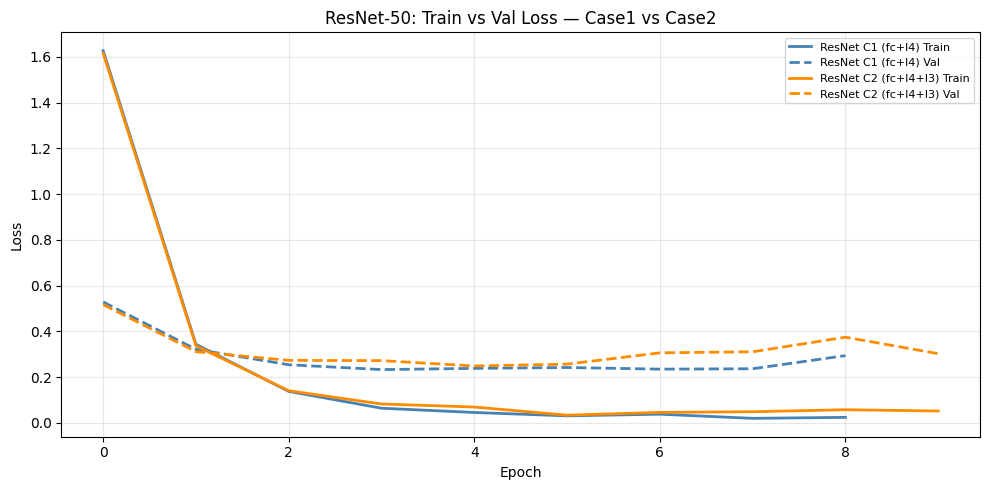

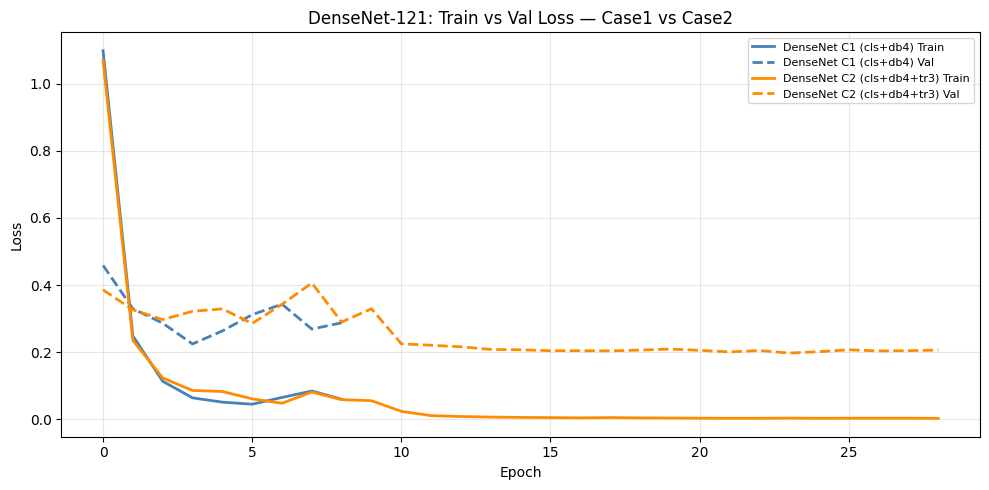

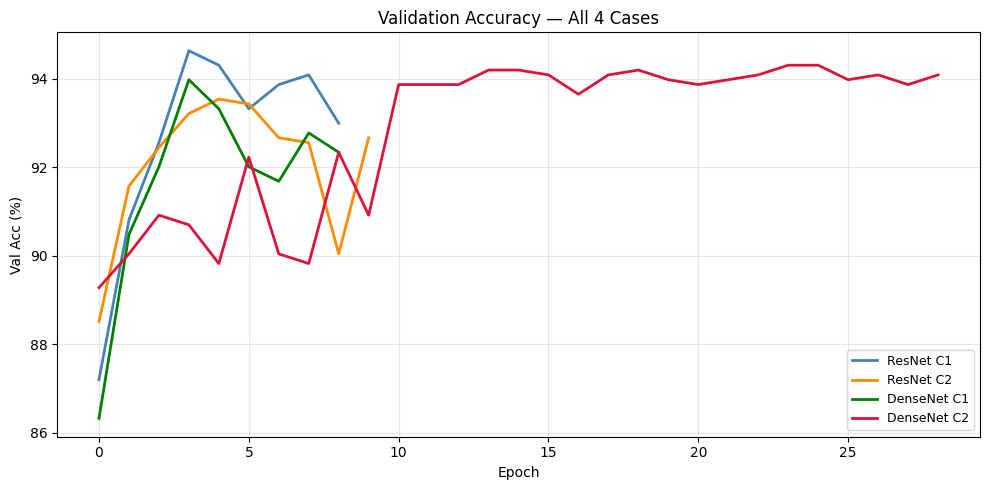

In [12]:
# ResNet: Case1 vs Case2 — shows effect of unfreezing one extra layer
plot_loss_curves(
    [res_c1_hist, res_c2_hist],
    ["ResNet C1 (fc+l4)", "ResNet C2 (fc+l4+l3)"],
    "ResNet-50: Train vs Val Loss — Case1 vs Case2"
)

# DenseNet: Case1 vs Case2
plot_loss_curves(
    [den_c1_hist, den_c2_hist],
    ["DenseNet C1 (cls+db4)", "DenseNet C2 (cls+db4+tr3)"],
    "DenseNet-121: Train vs Val Loss — Case1 vs Case2"
)

# All 4 val accuracy overlaid — direct comparison across models and cases
plot_val_acc(
    [res_c1_hist, res_c2_hist, den_c1_hist, den_c2_hist],
    ["ResNet C1", "ResNet C2", "DenseNet C1", "DenseNet C2"],
    "Validation Accuracy — All 4 Cases"
)

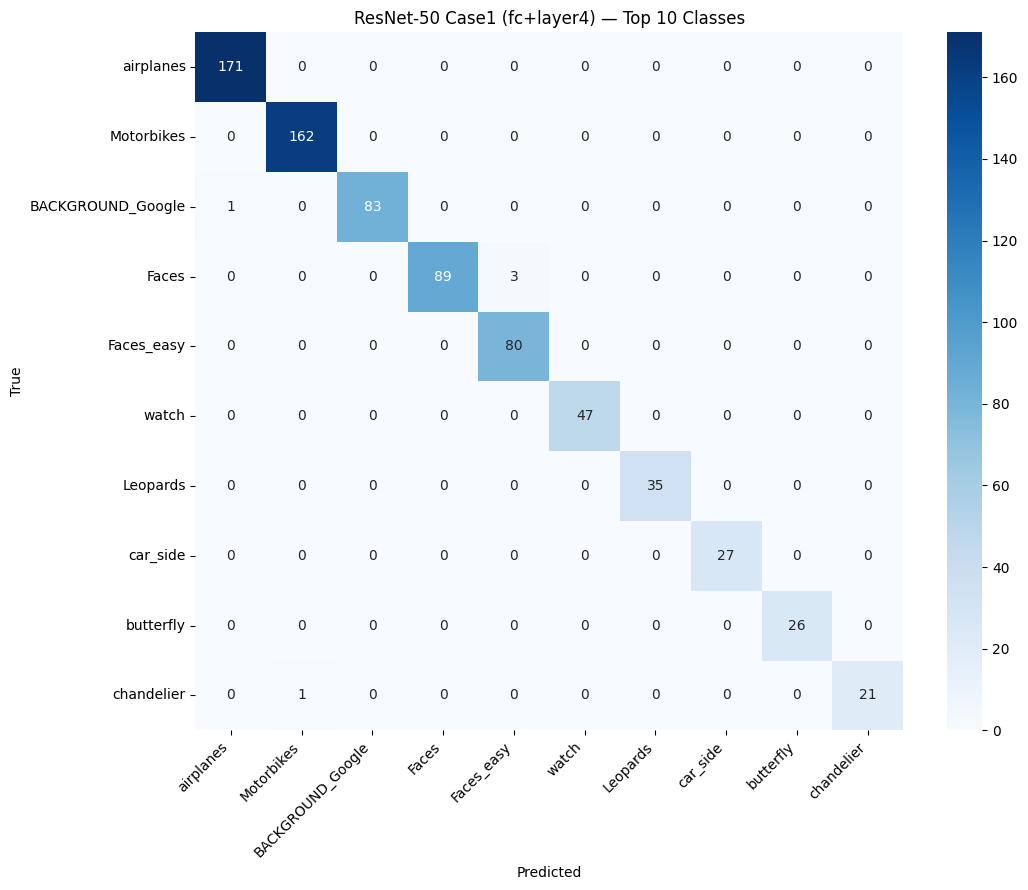

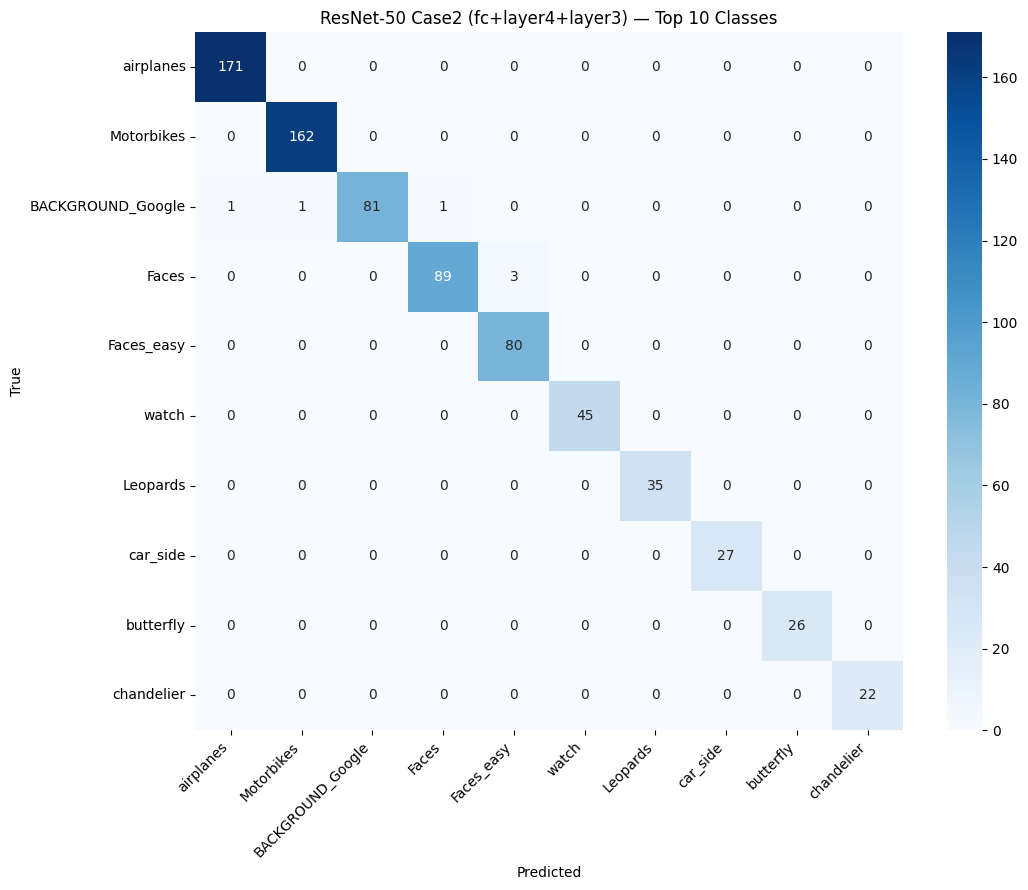

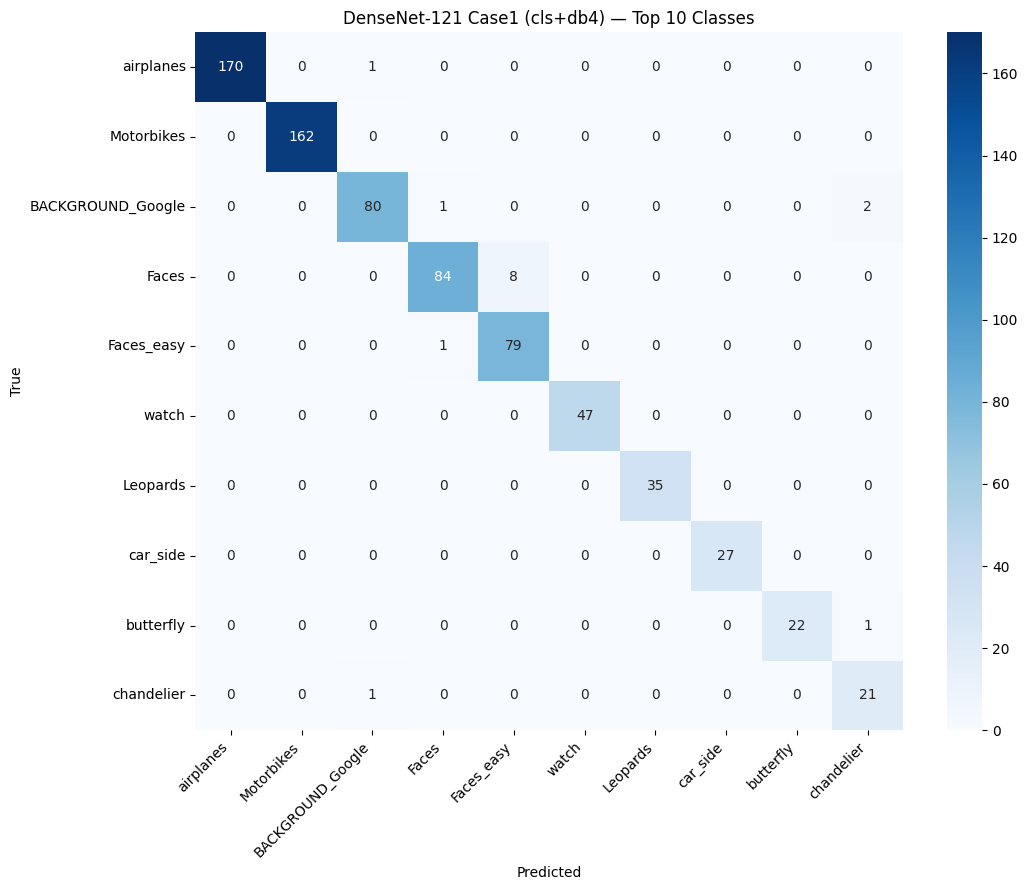

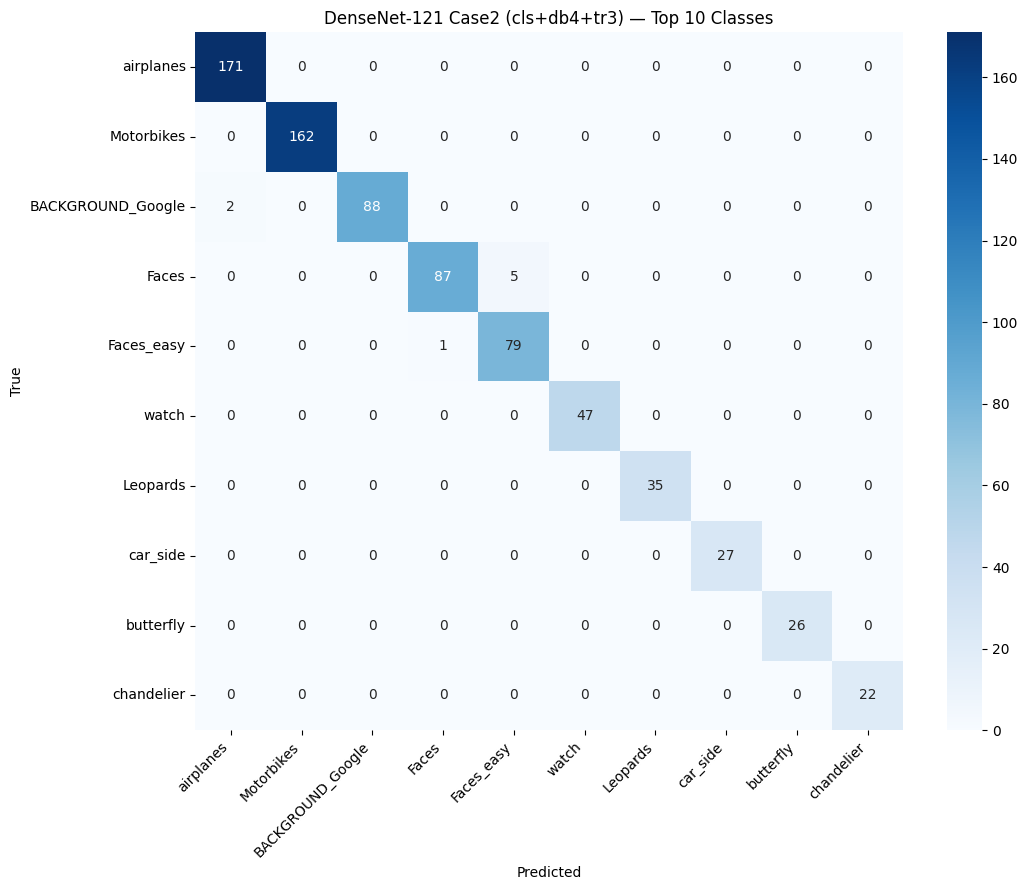

In [14]:
plot_top10_confusion(cm_rc1, classes, "ResNet-50 Case1 (fc+layer4) — Top 10 Classes")
plot_top10_confusion(cm_rc2, classes, "ResNet-50 Case2 (fc+layer4+layer3) — Top 10 Classes")
plot_top10_confusion(cm_dc1, classes, "DenseNet-121 Case1 (cls+db4) — Top 10 Classes")
plot_top10_confusion(cm_dc2, classes, "DenseNet-121 Case2 (cls+db4+tr3) — Top 10 Classes")

In [15]:
try:
    from thop import profile
    dummy = torch.zeros(1, 3, 224, 224).to(Config.DEVICE)
    r_macs, _ = profile(res_c1_model, inputs=(dummy,), verbose=False)
    d_macs, _ = profile(den_c1_model, inputs=(dummy,), verbose=False)
    res_gflops = r_macs * 2 / 1e9
    den_gflops = d_macs * 2 / 1e9
except ImportError:
    res_gflops, den_gflops = 4.1, 2.9
    print("thop not found — using literature GFLOPs")

print("\n" + "="*78)
print("COMPARATIVE ANALYSIS — Standard Fine-tuning (All 4 Cases)")
print("="*78)
print(f"{'Metric':<28} {'ResNet C1':>11} {'ResNet C2':>11} {'DenseNet C1':>12} {'DenseNet C2':>12}")
print("-"*78)
print(f"{'Unfrozen':<28} {'fc+l4':>11} {'fc+l4+l3':>11} {'cls+db4':>12} {'cls+db4+tr3':>12}")
print(f"{'Optimizer':<28} {'Adam':>11} {'Adam':>11} {'Adam':>12} {'Adam':>12}")
print(f"{'LR':<28} {'1e-4':>11} {'1e-4':>11} {'1e-3':>12} {'1e-3':>12}")
print(f"{'GFLOPs':<28} {res_gflops:>11.1f} {res_gflops:>11.1f} {den_gflops:>12.1f} {den_gflops:>12.1f}")
print(f"{'Total Params':<28} {res_c1_total:>11,} {res_c2_total:>11,} {den_c1_total:>12,} {den_c2_total:>12,}")
print(f"{'Trainable Params':<28} {res_c1_train:>11,} {res_c2_train:>11,} {den_c1_train:>12,} {den_c2_train:>12,}")
print(f"{'Trainable %':<28} "
      f"{100*res_c1_train/res_c1_total:>10.1f}% "
      f"{100*res_c2_train/res_c2_total:>10.1f}% "
      f"{100*den_c1_train/den_c1_total:>11.1f}% "
      f"{100*den_c2_train/den_c2_total:>11.1f}%")
print(f"{'Best Val Acc (%)':<28} {res_c1_best:>11.2f} {res_c2_best:>11.2f} {den_c1_best:>12.2f} {den_c2_best:>12.2f}")
print(f"{'Test Acc (%)':<28} {acc_rc1:>11.2f} {acc_rc2:>11.2f} {acc_dc1:>12.2f} {acc_dc2:>12.2f}")
print(f"{'Macro F1':<28} {f1_rc1:>11.4f} {f1_rc2:>11.4f} {f1_dc1:>12.4f} {f1_dc2:>12.4f}")
print(f"{'Training Time (s)':<28} {res_c1_time:>11.1f} {res_c2_time:>11.1f} {den_c1_time:>12.1f} {den_c2_time:>12.1f}")
print(f"{'Time/Epoch (s)':<28} "
      f"{res_c1_time/len(res_c1_hist['train_loss']):>11.1f} "
      f"{res_c2_time/len(res_c2_hist['train_loss']):>11.1f} "
      f"{den_c1_time/len(den_c1_hist['train_loss']):>12.1f} "
      f"{den_c2_time/len(den_c2_hist['train_loss']):>12.1f}")

thop not found — using literature GFLOPs

COMPARATIVE ANALYSIS — Standard Fine-tuning (All 4 Cases)
Metric                         ResNet C1   ResNet C2  DenseNet C1  DenseNet C2
------------------------------------------------------------------------------
Unfrozen                           fc+l4    fc+l4+l3      cls+db4  cls+db4+tr3
Optimizer                           Adam        Adam         Adam         Adam
LR                                  1e-4        1e-4         1e-3         1e-3
GFLOPs                               4.1         4.1          2.9          2.9
Total Params                  23,717,030  23,717,030    7,058,406    7,058,406
Trainable Params              15,173,734  22,272,102    2,262,630    2,788,966
Trainable %                        64.0%       93.9%        32.1%        39.5%
Best Val Acc (%)                   94.64       93.54        93.98        94.31
Test Acc (%)                       93.28       92.51        90.93        93.61
Macro F1                       

In [16]:
# Fixed best hyperparams from HP search — no AdaptConfig.LR anymore (per-model now)
class AdaptConfig:
    # ResNet-50 best: Adam lr=1e-4, StepLR
    RES_LR       = 1e-4
    # DenseNet-121 best: Adam lr=1e-3, StepLR
    DEN_LR       = 1e-3

          
    WEIGHT_DECAY = 1e-4     # L2 reg — same for both
    EPOCHS       = 50
    PATIENCE     = 5
    STEP_SIZE    = 10       # StepLR: decay every 10 epochs
    GAMMA        = 0.1      # StepLR: lr × 0.1 at each step
    TOP_FRAC     = 0.25     # top 25% filters from last conv block

print("AdaptConfig loaded.")
print(f"  ResNet-50  : Adam | lr={AdaptConfig.RES_LR} | StepLR")
print(f"  DenseNet121: Adam | lr={AdaptConfig.DEN_LR} | StepLR")

AdaptConfig loaded.
  ResNet-50  : Adam | lr=0.0001 | StepLR
  DenseNet121: Adam | lr=0.001 | StepLR


In [17]:
# ── Assignment says: "last convolutional block" specifically ──────────────
# ResNet-50   last conv block = model.layer4  (3 Bottleneck blocks, each has conv1/conv2/conv3)
# DenseNet121 last conv block = model.features.denseblock4  (dense layers with conv1/conv2)
# We hook only Conv2d layers INSIDE that block, not the entire network

def compute_lastblock_importance(model, loader, device, model_name):
    """
    Hooks Conv2d layers in the LAST convolutional block only.
    Computes mean(|activation|) per filter per batch, averages across all batches.
    Returns: dict {layer_name -> tensor[C_out]}
    """
    model.eval()
    buffers, handles = {}, []

    # Identify last conv block by model architecture
    if model_name == "resnet50":
        last_block = model.layer4          # last residual group (3 Bottlenecks)
    elif model_name == "densenet121":
        last_block = model.features.denseblock4  # last dense block

    # Register hooks ONLY on Conv2d inside last block
    for name, module in last_block.named_modules():
        if isinstance(module, nn.Conv2d):
            buffers[name] = []             # accumulate per-batch activations here

            def make_hook(n):
                def hook_fn(mod, inp, out):
                    # out: [B, C_out, H, W] → average over batch dim + spatial → [C_out]
                    buffers[n].append(out.detach().abs().mean(dim=(0, 2, 3)).cpu())
                return hook_fn

            handles.append(module.register_forward_hook(make_hook(name)))

    print(f"  Hooks registered on {len(handles)} Conv2d layers in last block...")

    with torch.no_grad():
        for imgs, _ in loader:
            model(imgs.to(device))         # full forward pass — hooks capture activations

    for h in handles:
        h.remove()                         # always remove hooks — prevents memory leak

    # Average each filter's magnitude across all batches → one score per filter
    importance = {
        name: torch.stack(acts).mean(0)    # [num_batches, C_out] → [C_out]
        for name, acts in buffers.items()
    }

    total_filters = sum(v.shape[0] for v in importance.values())
    print(f"  Done. Layers captured: {len(importance)} | Total filters: {total_filters}")
    return importance


def select_top_filters(importance_dict, top_frac=0.25):
    """
    Flatten ALL filter scores from last block → global threshold at (1-top_frac) quantile.
    Top 25% by magnitude = most activated filters = most important for this dataset.
    """
    all_scores = torch.cat(list(importance_dict.values()))   # all last-block filters
    threshold  = torch.quantile(all_scores, 1.0 - top_frac) # 75th percentile cutoff
    n_selected = (all_scores >= threshold).sum().item()
    print(f"  Threshold: {threshold:.4f} | Selected: {n_selected}/{len(all_scores)} ({top_frac*100:.0f}%)")
    return threshold


print("Importance functions defined.")

Importance functions defined.


In [18]:
def apply_adaptive_finetuning(model, importance_dict, threshold, model_name):
    """
    Freeze all → unfreeze classifier head → gradient-mask top-25% filters
    in the last conv block. Filters below threshold get zero gradient.
    importance_dict keys are LOCAL names within last_block (e.g. '0.conv1').
    We match them by iterating the same last_block.
    """
    # Step 1: freeze everything
    for p in model.parameters():
        p.requires_grad = False

    # Step 2: always unfreeze classifier head — task-specific, must adapt
    if model_name == "resnet50":
        for p in model.fc.parameters():
            p.requires_grad = True
        last_block = model.layer4
    elif model_name == "densenet121":
        for p in model.classifier.parameters():
            p.requires_grad = True
        last_block = model.features.denseblock4

    # Step 3: selective gradient masking on last block Conv2d filters
    n_adapted = 0
    for name, module in last_block.named_modules():
        if isinstance(module, nn.Conv2d) and name in importance_dict:
            scores = importance_dict[name]           # [C_out] scores for this layer
            mask   = (scores >= threshold).float()   # binary: 1=important, 0=ignore

            if mask.sum() == 0:
                continue   # no filters selected in this layer — skip

            module.weight.requires_grad = True       # enable grad (hook will zero unimportant)

            def make_grad_hook(m):
                def grad_hook(grad):
                    # grad shape: [C_out, C_in, kH, kW]
                    # multiply each output filter's gradient by mask (0 or 1)
                    return grad * m.to(grad.device).view(-1, 1, 1, 1)
                return grad_hook

            module.weight.register_hook(make_grad_hook(mask))  # fires every backward pass
            n_adapted += int(mask.sum().item())

    total_p   = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"  Filters adapted (last block): {n_adapted}")
    print(f"  Trainable params: {trainable:,} / {total_p:,} ({100*trainable/total_p:.2f}%)")
    return model


print("Adaptive unfreezing defined.")

Adaptive unfreezing defined.


In [19]:
def train_adaptive(model, train_loader, val_loader, device, label, lr):
    """
    Training loop using Adam + StepLR (best config from HP search).
    lr passed per model: ResNet=1e-4, DenseNet=1e-3.
    Early stopping on val_acc with patience=5.
    """
    criterion = nn.CrossEntropyLoss()

    # Adam: adaptive lr per parameter — better than SGD for fine-tuning small layers
    optimizer = torch.optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr,
        weight_decay=AdaptConfig.WEIGHT_DECAY
    )

    # StepLR: multiply lr by 0.1 every 10 epochs — matches HP search best config
    scheduler = torch.optim.lr_scheduler.StepLR(
        optimizer,
        step_size=AdaptConfig.STEP_SIZE,
        gamma=AdaptConfig.GAMMA
    )

    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    best_val_acc = 0.0
    best_state   = None
    patience_ctr = 0
    total_time   = 0.0

    for epoch in range(AdaptConfig.EPOCHS):
        t0 = time.time()

        # ── Train ──────────────────────────────────────────────
        model.train()
        running_loss = 0.0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(imgs), labels)
            loss.backward()            # gradient hooks zero unimportant filter grads
            optimizer.step()
            running_loss += loss.item()
        train_loss = running_loss / len(train_loader)

        # ── Validate ────────────────────────────────────────────
        model.eval()
        val_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                out = model(imgs)
                val_loss += criterion(out, labels).item()
                correct  += (out.argmax(1) == labels).sum().item()
                total    += labels.size(0)
        val_loss /= len(val_loader)
        val_acc   = 100 * correct / total

        scheduler.step()              # StepLR steps unconditionally each epoch

        epoch_time  = time.time() - t0
        total_time += epoch_time

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(f"{label} | Epoch {epoch+1:02d} | "
              f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | "
              f"Val Acc: {val_acc:.2f}% | "
              f"LR: {optimizer.param_groups[0]['lr']:.2e} | "
              f"Time: {epoch_time:.1f}s")

        # Early stopping on val_acc — save best state
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state   = {k: v.clone() for k, v in model.state_dict().items()}
            patience_ctr = 0
        else:
            patience_ctr += 1
            if patience_ctr >= AdaptConfig.PATIENCE:
                print(f"  Early stopping at epoch {epoch+1} | Best: {best_val_acc:.2f}%")
                break

    model.load_state_dict(best_state)   # restore best before evaluation
    print(f"\n  Total time ({label}): {total_time:.1f}s | Best Val Acc: {best_val_acc:.2f}%")
    return model, history, best_val_acc, total_time


print("Training function defined.")

Training function defined.


In [20]:

# =====================================================
# STEP 4: Evaluation helpers (Top-1, F1, Confusion Matrix)
# =====================================================

def evaluate_model(model, loader, device, dataset_classes):
    """Returns (acc, f1, confusion_matrix, y_true, y_pred)."""
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs  = imgs.to(device)
            preds = model(imgs).argmax(1).cpu()
            y_true.extend(labels.tolist())
            y_pred.extend(preds.tolist())

    acc = 100 * sum(t == p for t, p in zip(y_true, y_pred)) / len(y_true)
    f1  = f1_score(y_true, y_pred, average="macro", zero_division=0)
    cm  = confusion_matrix(y_true, y_pred)
    return acc, f1, cm, y_true, y_pred


def plot_curves(hist, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
    ax1.plot(hist["train_loss"], label="Train Loss", lw=2)
    ax1.plot(hist["val_loss"],   label="Val Loss",   lw=2, ls="--")
    ax1.set_title(f"{title} — Loss"); ax1.legend(); ax1.grid(True, alpha=0.3)
    ax2.plot(hist["val_acc"], label="Val Acc", color="green", lw=2)
    ax2.set_title(f"{title} — Val Accuracy"); ax2.legend(); ax2.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()


def plot_top10_confusion(cm, classes, title):
    """Confusion matrix sliced to top-10 most populated classes."""
    top10_idx = np.argsort(cm.sum(axis=1))[-10:][::-1]
    cm10      = cm[np.ix_(top10_idx, top10_idx)]
    labels10  = [classes[i] for i in top10_idx]

    plt.figure(figsize=(10, 8))
    sns.heatmap(cm10, annot=True, fmt="d",
                xticklabels=labels10, yticklabels=labels10, cmap="Blues")
    plt.title(title); plt.ylabel("True"); plt.xlabel("Predicted")
    plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()


def param_summary(model, label):
    total     = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"{label} | Total: {total:,} | Trainable: {trainable:,} ({100*trainable/total:.2f}%)")
    return total, trainable


print("Helpers defined.")


Helpers defined.


In [21]:
# =====================================================
# STEP 5: Count parameters (total vs trainable)
# =====================================================

def param_summary(model, label):
    total     = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"{label} | Total: {total:,} | Trainable: {trainable:,} ({100*trainable/total:.2f}%)")
    return total, trainable



In [22]:
print("=" * 60)
print("ADAPTIVE FINETUNING: ResNet-50")
print("  Optimizer: Adam | LR: 1e-4 | Scheduler: StepLR")
print("  Importance: last conv block (layer4) | Top 25%")
print("=" * 60)

model_res_adapt = get_model("resnet50", num_classes).to(device)
freeze_all(model_res_adapt)   # full freeze before importance pass

print("\n[1] Computing filter importance — ResNet-50 (layer4 only)...")
importance_res = compute_lastblock_importance(model_res_adapt, train_loader, device, "resnet50")
threshold_res  = select_top_filters(importance_res, AdaptConfig.TOP_FRAC)

print("\n[2] Applying adaptive unfreezing...")
model_res_adapt = apply_adaptive_finetuning(
    model_res_adapt, importance_res, threshold_res, "resnet50"
)
res_total_p, res_train_p = param_summary(model_res_adapt, "ResNet-50 Adaptive")

print("\n[3] Training...")
model_res_adapt, hist_res_adapt, best_res_adapt, time_res_adapt = train_adaptive(
    model_res_adapt, train_loader, val_loader,
    device, "ResNet-50 Adaptive", AdaptConfig.RES_LR    # Adam lr=1e-4
)

ADAPTIVE FINETUNING: ResNet-50
  Optimizer: Adam | LR: 1e-4 | Scheduler: StepLR
  Importance: last conv block (layer4) | Top 25%

[1] Computing filter importance — ResNet-50 (layer4 only)...
  Hooks registered on 10 Conv2d layers in last block...
  Done. Layers captured: 10 | Total filters: 11264
  Threshold: 0.0916 | Selected: 2816/11264 (25%)

[2] Applying adaptive unfreezing...
  Filters adapted (last block): 2816
  Trainable params: 15,151,206 / 23,717,030 (63.88%)
ResNet-50 Adaptive | Total: 23,717,030 | Trainable: 15,151,206 (63.88%)

[3] Training...
ResNet-50 Adaptive | Epoch 01 | Train Loss: 2.4570 | Val Loss: 1.3256 | Val Acc: 73.41% | LR: 1.00e-04 | Time: 11.6s
ResNet-50 Adaptive | Epoch 02 | Train Loss: 0.9750 | Val Loss: 0.6926 | Val Acc: 87.20% | LR: 1.00e-04 | Time: 11.4s
ResNet-50 Adaptive | Epoch 03 | Train Loss: 0.6273 | Val Loss: 0.5680 | Val Acc: 89.50% | LR: 1.00e-04 | Time: 11.4s
ResNet-50 Adaptive | Epoch 04 | Train Loss: 0.5634 | Val Loss: 0.5914 | Val Acc: 90.37

In [23]:
# Save best trained model
torch.save(model_res_adapt.state_dict(), "resnet50_adaptive.pth")


In [24]:
print("=" * 60)
print("ADAPTIVE FINETUNING: DenseNet-121")
print("  Optimizer: Adam | LR: 1e-3 | Scheduler: StepLR")
print("  Importance: last conv block (denseblock4) | Top 25%")
print("=" * 60)

model_den_adapt = get_model("densenet121", num_classes).to(device)
freeze_all(model_den_adapt)

print("\n[1] Computing filter importance — DenseNet-121 (denseblock4 only)...")
importance_den = compute_lastblock_importance(model_den_adapt, train_loader, device, "densenet121")
threshold_den  = select_top_filters(importance_den, AdaptConfig.TOP_FRAC)

print("\n[2] Applying adaptive unfreezing...")
model_den_adapt = apply_adaptive_finetuning(
    model_den_adapt, importance_den, threshold_den, "densenet121"
)
den_total_p, den_train_p = param_summary(model_den_adapt, "DenseNet-121 Adaptive")

print("\n[3] Training...")
model_den_adapt, hist_den_adapt, best_den_adapt, time_den_adapt = train_adaptive(
    model_den_adapt, train_loader, val_loader,
    device, "DenseNet-121 Adaptive", AdaptConfig.DEN_LR  # Adam lr=1e-3
)

ADAPTIVE FINETUNING: DenseNet-121
  Optimizer: Adam | LR: 1e-3 | Scheduler: StepLR
  Importance: last conv block (denseblock4) | Top 25%

[1] Computing filter importance — DenseNet-121 (denseblock4 only)...
  Hooks registered on 32 Conv2d layers in last block...
  Done. Layers captured: 32 | Total filters: 2560
  Threshold: 0.0459 | Selected: 640/2560 (25%)

[2] Applying adaptive unfreezing...
  Filters adapted (last block): 640
  Trainable params: 1,865,830 / 7,058,406 (26.43%)
DenseNet-121 Adaptive | Total: 7,058,406 | Trainable: 1,865,830 (26.43%)

[3] Training...
DenseNet-121 Adaptive | Epoch 01 | Train Loss: 1.5876 | Val Loss: 0.5851 | Val Acc: 88.07% | LR: 1.00e-03 | Time: 11.3s
DenseNet-121 Adaptive | Epoch 02 | Train Loss: 0.4245 | Val Loss: 0.3697 | Val Acc: 90.04% | LR: 1.00e-03 | Time: 11.1s
DenseNet-121 Adaptive | Epoch 03 | Train Loss: 0.1998 | Val Loss: 0.2868 | Val Acc: 91.68% | LR: 1.00e-03 | Time: 11.1s
DenseNet-121 Adaptive | Epoch 04 | Train Loss: 0.1089 | Val Loss: 

In [25]:
SAVE_PATH_DEN = "best_densenet121_adaptive.pth"
torch.save(model_den_adapt.state_dict(), SAVE_PATH_DEN)


TEST SET EVALUATION — Adaptive Finetuning

ResNet-50    | Test Acc: 91.26% | Macro F1: 0.8431 | Trainable: 15,151,206 | Time: 114.4s
DenseNet-121 | Test Acc: 92.68% | Macro F1: 0.8952 | Trainable: 1,865,830 | Time: 287.0s


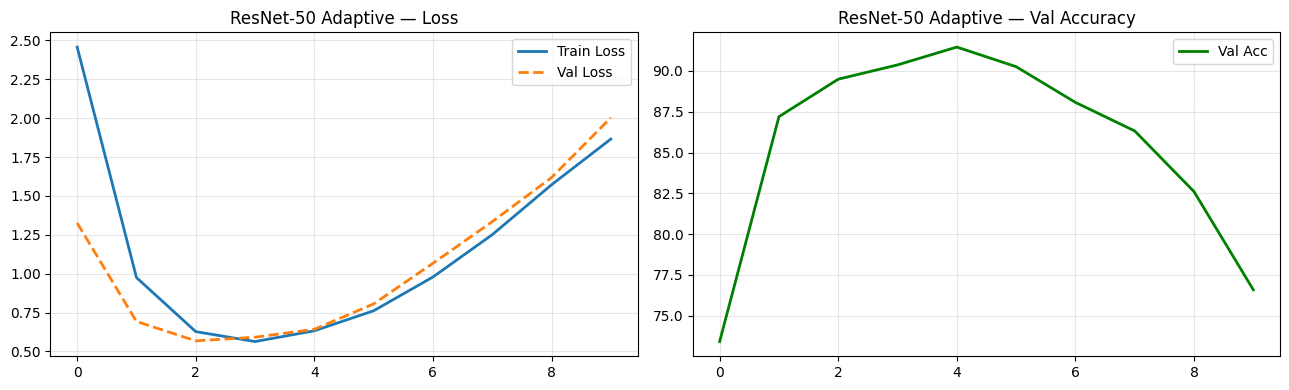

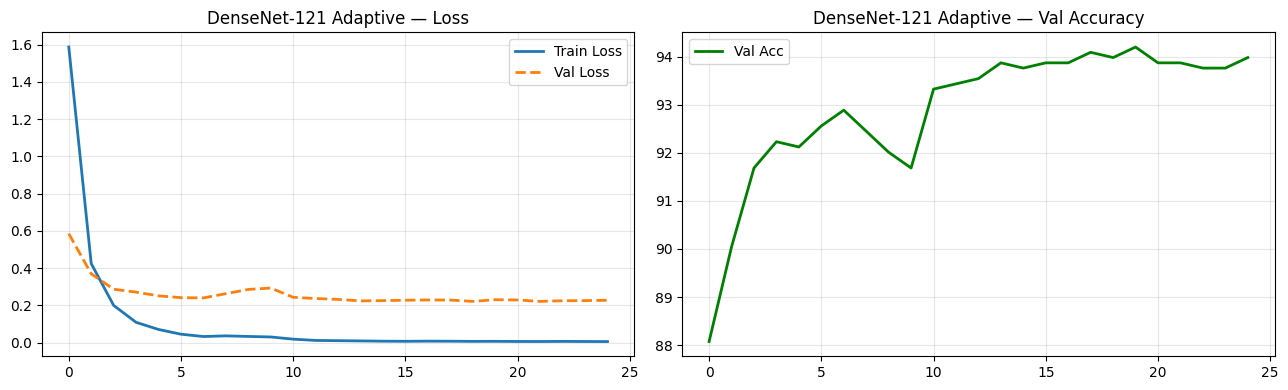

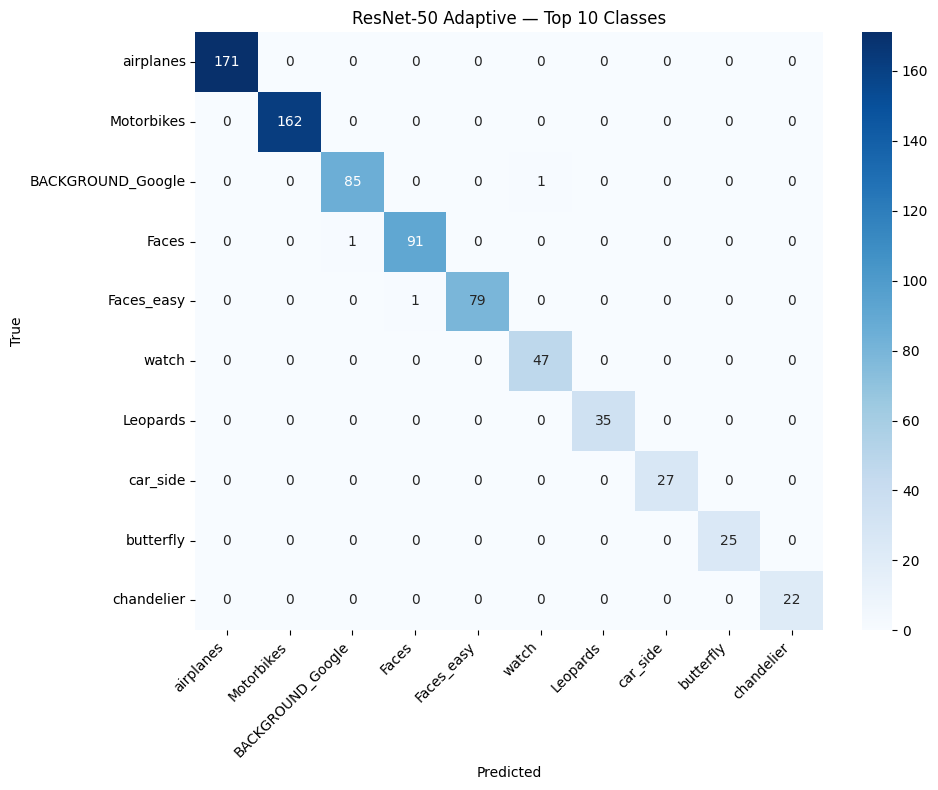

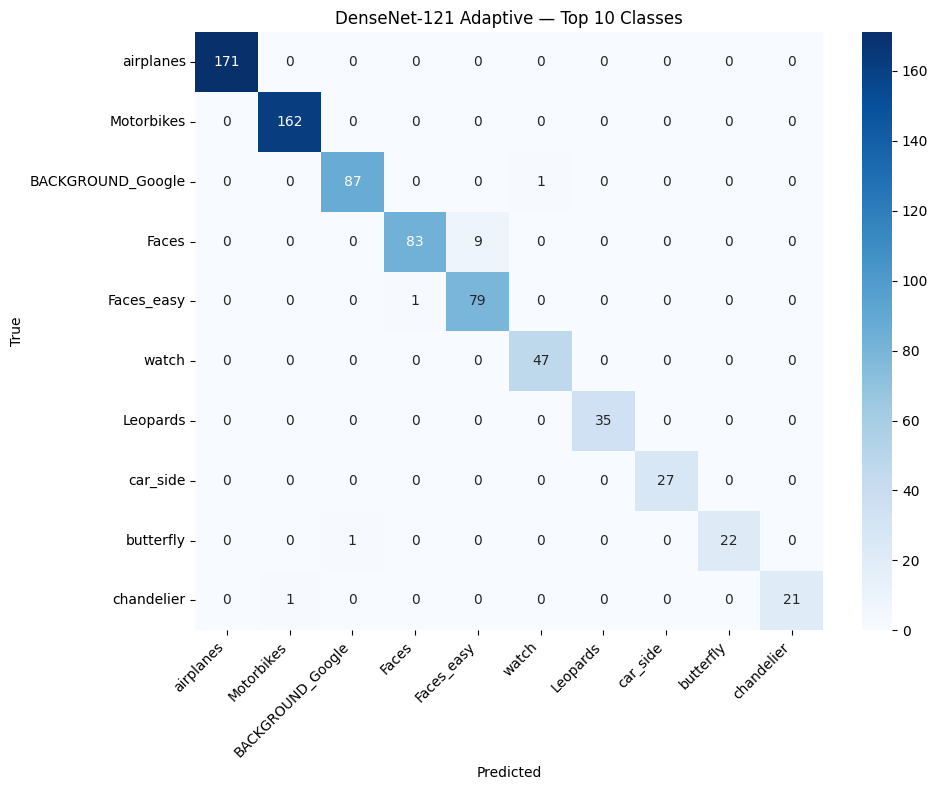

In [26]:
# =====================================================
# STEP 8: Evaluate on Test Set + Plots
# =====================================================

print("\n" + "=" * 60)
print("TEST SET EVALUATION — Adaptive Finetuning")
print("=" * 60)

classes = dataset.classes   # 102 class names from ImageFolder

acc_res, f1_res, cm_res, _, _ = evaluate_model(model_res_adapt, test_loader, device, classes)
acc_den, f1_den, cm_den, _, _ = evaluate_model(model_den_adapt, test_loader, device, classes)

print(f"\nResNet-50    | Test Acc: {acc_res:.2f}% | Macro F1: {f1_res:.4f} | "
      f"Trainable: {res_train_p:,} | Time: {time_res_adapt:.1f}s")
print(f"DenseNet-121 | Test Acc: {acc_den:.2f}% | Macro F1: {f1_den:.4f} | "
      f"Trainable: {den_train_p:,} | Time: {time_den_adapt:.1f}s")

# Loss + accuracy curves
plot_curves(hist_res_adapt, "ResNet-50 Adaptive")
plot_curves(hist_den_adapt, "DenseNet-121 Adaptive")

# Top-10 confusion matrices
plot_top10_confusion(cm_res, classes, "ResNet-50 Adaptive — Top 10 Classes")
plot_top10_confusion(cm_den, classes, "DenseNet-121 Adaptive — Top 10 Classes")

In [27]:
# =====================================================
# STEP 9: Comparative Summary Table
# Covers: params, time, accuracy — all rubric points
# =====================================================

print("\n" + "=" * 65)
print("COMPARATIVE ANALYSIS — Adaptive Finetuning")
print("=" * 65)
print(f"{'Metric':<32} {'ResNet-50':>15} {'DenseNet-121':>15}")
print("-" * 65)
print(f"{'Importance Block':<32} {'layer4':>15} {'denseblock4':>15}")
print(f"{'Optimizer':<32} {'Adam':>15} {'Adam':>15}")
print(f"{'Learning Rate':<32} {'1e-4':>15} {'1e-3':>15}")
print(f"{'Scheduler':<32} {'StepLR':>15} {'StepLR':>15}")
print(f"{'Total Params':<32} {res_total_p:>15,} {den_total_p:>15,}")
print(f"{'Trainable Params':<32} {res_train_p:>15,} {den_train_p:>15,}")
print(f"{'Trainable %':<32} {100*res_train_p/res_total_p:>14.2f}% {100*den_train_p/den_total_p:>14.2f}%")
print(f"{'Best Val Acc (%)':<32} {best_res_adapt:>15.2f} {best_den_adapt:>15.2f}")
print(f"{'Test Acc (%)':<32} {acc_res:>15.2f} {acc_den:>15.2f}")
print(f"{'Macro F1':<32} {f1_res:>15.4f} {f1_den:>15.4f}")
print(f"{'Training Time (s)':<32} {time_res_adapt:>15.1f} {time_den_adapt:>15.1f}")


COMPARATIVE ANALYSIS — Adaptive Finetuning
Metric                                 ResNet-50    DenseNet-121
-----------------------------------------------------------------
Importance Block                          layer4     denseblock4
Optimizer                                   Adam            Adam
Learning Rate                               1e-4            1e-3
Scheduler                                 StepLR          StepLR
Total Params                          23,717,030       7,058,406
Trainable Params                      15,151,206       1,865,830
Trainable %                               63.88%          26.43%
Best Val Acc (%)                           91.47           94.20
Test Acc (%)                               91.26           92.68
Macro F1                                  0.8431          0.8952
Training Time (s)                          114.4           287.0


In [28]:
# ── Save last-block results before running global file ──
model_res_lb    = model_res_adapt
model_den_lb    = model_den_adapt
hist_res_lb     = hist_res_adapt
hist_den_lb     = hist_den_adapt
best_res_lb     = best_res_adapt
best_den_lb     = best_den_adapt
time_res_lb     = time_res_adapt
time_den_lb     = time_den_adapt
res_total_lb    = res_total_p
res_train_lb    = res_train_p
den_total_lb    = den_total_p
den_train_lb    = den_train_p

print("Last-block variables saved.")

Last-block variables saved.


In [37]:
# Best configs from HP search — hardcoded, 
class AdaptConfig:
    # ResNet-50 best: Adam lr=1e-4, StepLR
    RES_LR       = 1e-4
    # DenseNet-121 best: Adam lr=1e-3, StepLR
    DEN_LR       = 1e-3

    WEIGHT_DECAY = 1e-4
    EPOCHS       = 50
    PATIENCE     = 5
    STEP_SIZE    = 10      # StepLR: decay every 10 epochs
    GAMMA        = 0.1     # lr × 0.1 at each step
    TOP_FRAC     = 0.25    # top 25% filters globally

print("AdaptConfig loaded.")
print(f"  ResNet-50   : Adam | lr={AdaptConfig.RES_LR} | StepLR")
print(f"  DenseNet-121: Adam | lr={AdaptConfig.DEN_LR} | StepLR")

AdaptConfig loaded.
  ResNet-50   : Adam | lr=0.0001 | StepLR
  DenseNet-121: Adam | lr=0.001 | StepLR


In [39]:
# =====================================================
# ADAPTIVE FINETUNING: Filter Importance Ranking
# Global Average Activation Magnitude across ALL filters

# =====================================================

# =====================================================
# STEP 1: Collect global filter activation magnitudes
# Strategy: register a forward hook on EVERY Conv2d layer,
#           accumulate mean(|output|) per filter across ALL batches,
#           then average over batches → one scalar per filter globally.
# We do NOT limit to last block — assignment asks global magnitude.
# =====================================================

def compute_global_importance(model, loader, device):
    """
    Hooks every Conv2d in the entire network.
    Computes mean(|activation|) per filter per batch → averages across all batches.
    Returns dict {layer_name -> tensor[C_out]} — one importance score per filter.
    """
    model.eval()
    buffers, handles = {}, []

    for name, module in model.named_modules():
        if isinstance(module, nn.Conv2d):
            buffers[name] = []

            def make_hook(n):
                def hook_fn(mod, inp, out):
                    # out: [B, C_out, H, W] → mean over batch+spatial → [C_out]
                    buffers[n].append(out.detach().abs().mean(dim=(0, 2, 3)).cpu())
                return hook_fn

            handles.append(module.register_forward_hook(make_hook(name)))

    print("  Running forward pass (full dataset)...")
    with torch.no_grad():
        for imgs, _ in loader:
            model(imgs.to(device))

    for h in handles:
        h.remove()   # must remove — else hooks accumulate across calls

    # Stack per-batch scores → average → one scalar per filter
    importance = {
        name: torch.stack(acts).mean(0)
        for name, acts in buffers.items()
    }
    total_filters = sum(v.shape[0] for v in importance.values())
    print(f"  Layers hooked: {len(importance)} | Total filters: {total_filters}")
    return importance


def select_top_filters_global(importance_dict, top_frac=0.25):
    """
    Concatenate ALL filter scores globally → single threshold at (1-top_frac) quantile.
    A filter in layer1 competes with one in layer4 on equal footing.
    Top 25% = most activated filters across the entire network on CalTech-101.
    """
    all_scores = torch.cat(list(importance_dict.values()))   # flatten all filters
    threshold  = torch.quantile(all_scores, 1.0 - top_frac) # 75th percentile
    n_selected = (all_scores >= threshold).sum().item()
    print(f"  Global threshold: {threshold:.4f} | "
          f"Selected: {n_selected}/{len(all_scores)} ({top_frac*100:.0f}%)")
    return threshold

print("Importance functions defined.")

Importance functions defined.


In [40]:
# =====================================================
# STEP 3: Apply adaptive unfreezing with gradient masking
# Only top-25% filters (globally ranked) get gradients.
# Classifier head always trainable (necessary for task adaptation).
# =====================================================


def apply_global_adaptive(model, importance_dict, threshold, model_name):
    """
    Freeze all → unfreeze classifier head → gradient-mask top-25% filters
    across the ENTIRE network (global ranking, not per-block).
    Unimportant filters get zero gradient via register_hook on weight tensor.
    """
    # Step 1: freeze everything
    for p in model.parameters():
        p.requires_grad = False

    # Step 2: always unfreeze head — task-specific, must adapt regardless
    if model_name == "resnet50":
        for p in model.fc.parameters():
            p.requires_grad = True
    elif model_name == "densenet121":
        for p in model.classifier.parameters():
            p.requires_grad = True

    # Step 3: gradient masking on globally selected filters
    n_filters_adapted = 0
    for name, module in model.named_modules():
        if isinstance(module, nn.Conv2d) and name in importance_dict:
            scores = importance_dict[name]          # [C_out]
            mask   = (scores >= threshold).float()  # 1=train, 0=freeze

            if mask.sum() == 0:
                continue   # no selected filters in this layer

            module.weight.requires_grad = True      # enable grad at layer level

            def make_grad_hook(m):
                def grad_hook(grad):
                    # grad: [C_out, C_in, kH, kW] — zero out unimportant filters
                    return grad * m.to(grad.device).view(-1, 1, 1, 1)
                return grad_hook

            module.weight.register_hook(make_grad_hook(mask))
            n_filters_adapted += int(mask.sum().item())

    total_p   = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"  Filters adapted (global): {n_filters_adapted}")
    print(f"  Trainable: {trainable:,} / {total_p:,} ({100*trainable/total_p:.2f}%)")
    return model, total_p, trainable

print("Global adaptive unfreezing defined.")

Global adaptive unfreezing defined.


In [41]:
# =====================================================
# STEP 4: Training loop with early stopping + timing
# SGD + StepLR as specified. Tracks: loss, acc, time.
# =====================================================

def train_global_adaptive(model, train_loader, val_loader, device, label, lr):
    """
    Adam + StepLR using best HP from search.
    lr passed per model: ResNet=1e-4, DenseNet=1e-3.
    Early stopping patience=5 on val_acc.
    """
    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr,
        weight_decay=AdaptConfig.WEIGHT_DECAY
    )

    # StepLR: divide lr by 10 every 10 epochs — matches HP search best config
    scheduler = torch.optim.lr_scheduler.StepLR(
        optimizer,
        step_size=AdaptConfig.STEP_SIZE,
        gamma=AdaptConfig.GAMMA
    )

    hist_global = {"train_loss": [], "val_loss": [], "val_acc": []}
    best_val_acc  = 0.0
    best_state    = None
    patience_ctr  = 0
    total_time    = 0.0

    for epoch in range(AdaptConfig.EPOCHS):
        t0 = time.time()

        # ── Train ──────────────────────────────────────────────
        model.train()
        running_loss = 0.0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(imgs), labels)
            loss.backward()        # grad hooks zero unimportant filter grads here
            optimizer.step()
            running_loss += loss.item()
        train_loss = running_loss / len(train_loader)

        # ── Validate ────────────────────────────────────────────
        model.eval()
        val_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                out = model(imgs)
                val_loss += criterion(out, labels).item()
                correct  += (out.argmax(1) == labels).sum().item()
                total    += labels.size(0)
        val_loss /= len(val_loader)
        val_acc   = 100 * correct / total

        scheduler.step()   # unconditional for StepLR

        epoch_time  = time.time() - t0
        total_time += epoch_time

        hist_global["train_loss"].append(train_loss)
        hist_global["val_loss"].append(val_loss)
        hist_global["val_acc"].append(val_acc)

        print(f"{label} | Epoch {epoch+1:02d} | "
              f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | "
              f"Val Acc: {val_acc:.2f}% | "
              f"LR: {optimizer.param_groups[0]['lr']:.2e} | "
              f"Time: {epoch_time:.1f}s")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state   = {k: v.clone() for k, v in model.state_dict().items()}
            patience_ctr = 0
        else:
            patience_ctr += 1
            if patience_ctr >= AdaptConfig.PATIENCE:
                print(f"  Early stopping at epoch {epoch+1} | Best: {best_val_acc:.2f}%")
                break

    model.load_state_dict(best_state)
    print(f"\n  Total time ({label}): {total_time:.1f}s | Best Val Acc: {best_val_acc:.2f}%")
    return model, hist_global, best_val_acc, total_time

print("Training function defined.")


Training function defined.


In [42]:
print("=" * 60)
print("GLOBAL ADAPTIVE FINETUNING: ResNet-50")
print("  Adam | lr=1e-4 | StepLR | Top 25% global filters")
print("=" * 60)

# Fresh pretrained model — don't reuse any previous model state
model_res_global = get_model("resnet50", num_classes).to(device)
freeze_all(model_res_global)

print("\n[1] Computing global filter importance (ResNet-50)...")
imp_res_global      = compute_global_importance(model_res_global, train_loader, device)
thresh_res_global   = select_top_filters_global(imp_res_global, AdaptConfig.TOP_FRAC)

print("\n[2] Applying global adaptive unfreezing...")
model_res_global, res_g_total, res_g_train = apply_global_adaptive(
    model_res_global, imp_res_global, thresh_res_global, "resnet50"
)

print("\n[3] Training...")
model_res_global, hist_res_global, best_res_global, time_res_global = train_global_adaptive(
    model_res_global, train_loader, val_loader,
    device, "ResNet-50 Global Adaptive", AdaptConfig.RES_LR
)

GLOBAL ADAPTIVE FINETUNING: ResNet-50
  Adam | lr=1e-4 | StepLR | Top 25% global filters

[1] Computing global filter importance (ResNet-50)...
  Running forward pass (full dataset)...
  Layers hooked: 53 | Total filters: 26560
  Global threshold: 0.1023 | Selected: 6640/26560 (25%)

[2] Applying global adaptive unfreezing...
  Filters adapted (global): 6640
  Trainable: 22,353,190 / 23,717,030 (94.25%)

[3] Training...
ResNet-50 Global Adaptive | Epoch 01 | Train Loss: 2.4007 | Val Loss: 1.2083 | Val Acc: 75.71% | LR: 1.00e-04 | Time: 25.7s
ResNet-50 Global Adaptive | Epoch 02 | Train Loss: 0.9241 | Val Loss: 0.6290 | Val Acc: 85.34% | LR: 1.00e-04 | Time: 25.6s
ResNet-50 Global Adaptive | Epoch 03 | Train Loss: 0.5542 | Val Loss: 0.6194 | Val Acc: 85.34% | LR: 1.00e-04 | Time: 25.7s
ResNet-50 Global Adaptive | Epoch 04 | Train Loss: 0.4632 | Val Loss: 0.6274 | Val Acc: 84.35% | LR: 1.00e-04 | Time: 25.7s
ResNet-50 Global Adaptive | Epoch 05 | Train Loss: 0.4226 | Val Loss: 0.6408 | V

In [43]:
print("=" * 60)
print("GLOBAL ADAPTIVE FINETUNING: DenseNet-121")
print("  Adam | lr=1e-3 | StepLR | Top 25% global filters")
print("=" * 60)

model_den_global = get_model("densenet121", num_classes).to(device)
freeze_all(model_den_global)

print("\n[1] Computing global filter importance (DenseNet-121)...")
imp_den_global      = compute_global_importance(model_den_global, train_loader, device)
thresh_den_global   = select_top_filters_global(imp_den_global, AdaptConfig.TOP_FRAC)

print("\n[2] Applying global adaptive unfreezing...")
model_den_global, den_g_total, den_g_train = apply_global_adaptive(
    model_den_global, imp_den_global, thresh_den_global, "densenet121"
)

print("\n[3] Training...")
model_den_global, hist_den_global, best_den_global, time_den_global = train_global_adaptive(
    model_den_global, train_loader, val_loader,
    device, "DenseNet-121 Global Adaptive", AdaptConfig.DEN_LR
)

GLOBAL ADAPTIVE FINETUNING: DenseNet-121
  Adam | lr=1e-3 | StepLR | Top 25% global filters

[1] Computing global filter importance (DenseNet-121)...
  Running forward pass (full dataset)...
  Layers hooked: 120 | Total filters: 10240
  Global threshold: 0.0811 | Selected: 2560/10240 (25%)

[2] Applying global adaptive unfreezing...
  Filters adapted (global): 2560
  Trainable: 5,537,062 / 7,058,406 (78.45%)

[3] Training...
DenseNet-121 Global Adaptive | Epoch 01 | Train Loss: 2.5452 | Val Loss: 2.5805 | Val Acc: 40.37% | LR: 1.00e-03 | Time: 29.5s
DenseNet-121 Global Adaptive | Epoch 02 | Train Loss: 1.6159 | Val Loss: 1.4747 | Val Acc: 61.49% | LR: 1.00e-03 | Time: 29.4s
DenseNet-121 Global Adaptive | Epoch 03 | Train Loss: 1.1762 | Val Loss: 1.3463 | Val Acc: 64.11% | LR: 1.00e-03 | Time: 29.4s
DenseNet-121 Global Adaptive | Epoch 04 | Train Loss: 0.8910 | Val Loss: 1.0919 | Val Acc: 71.23% | LR: 1.00e-03 | Time: 29.4s
DenseNet-121 Global Adaptive | Epoch 05 | Train Loss: 0.6887 | 


TEST EVALUATION — Global Adaptive Finetuning

ResNet-50    | Test Acc: 85.52% | F1: 0.7779 | Trainable: 22,353,190 | Time: 256.3s
DenseNet-121 | Test Acc: 84.59% | F1: 0.7677 | Trainable: 5,537,062 | Time: 666.8s


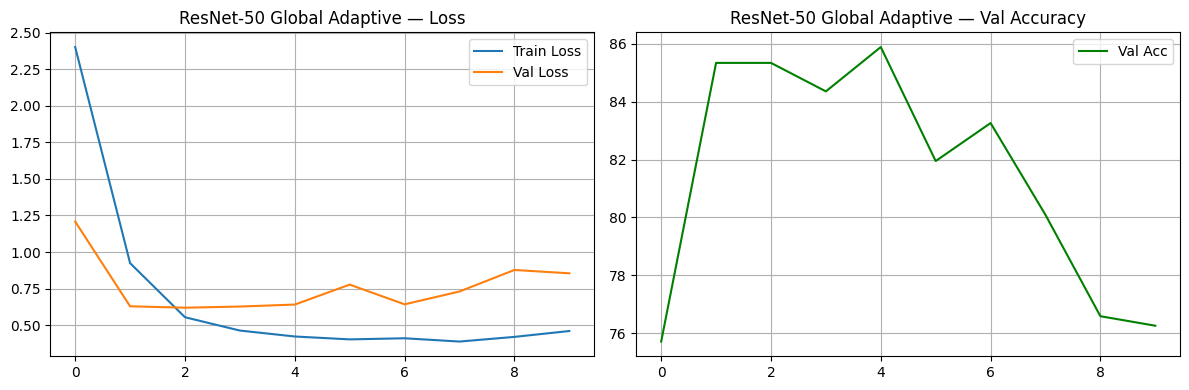

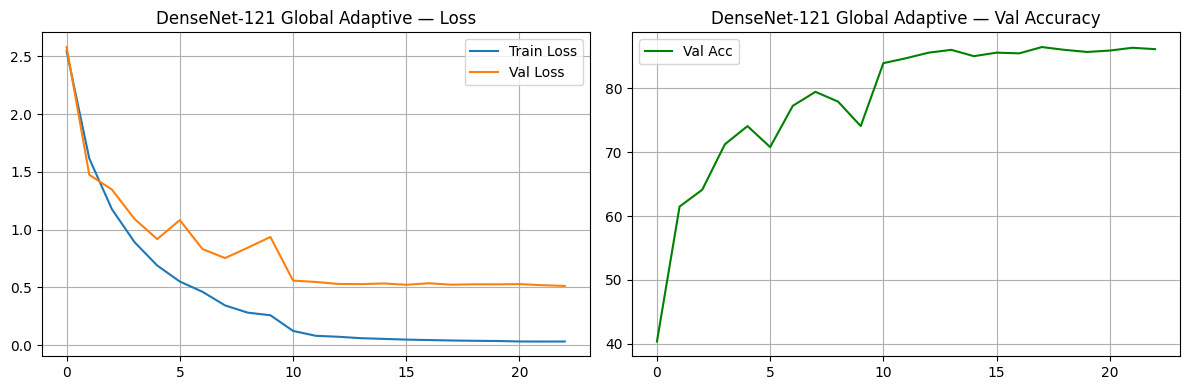

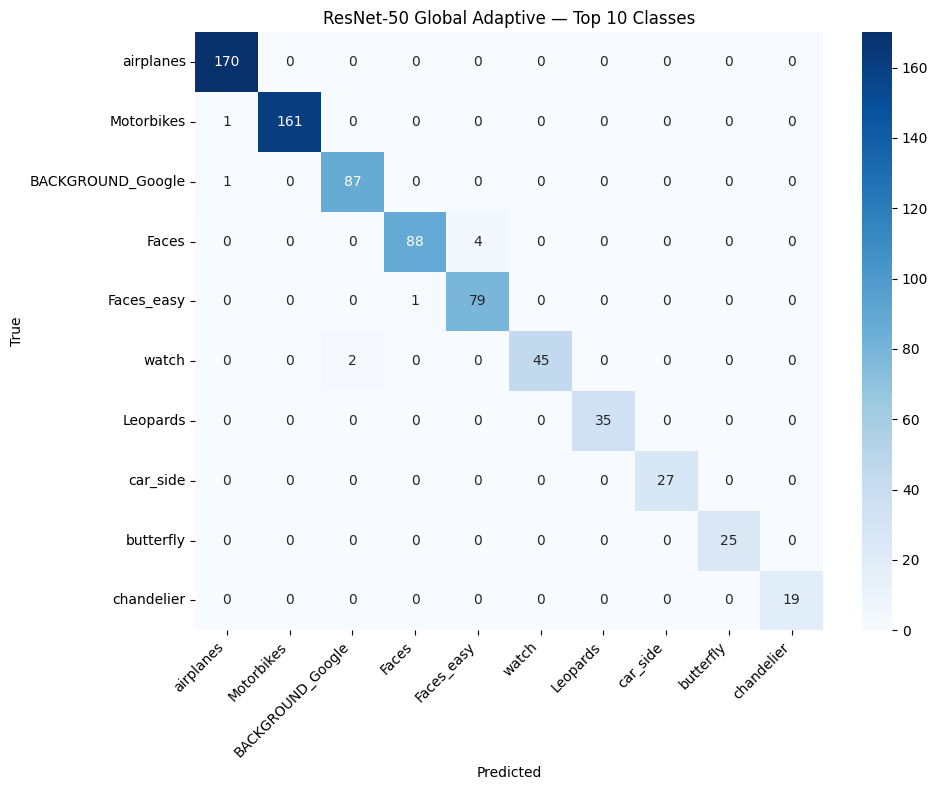

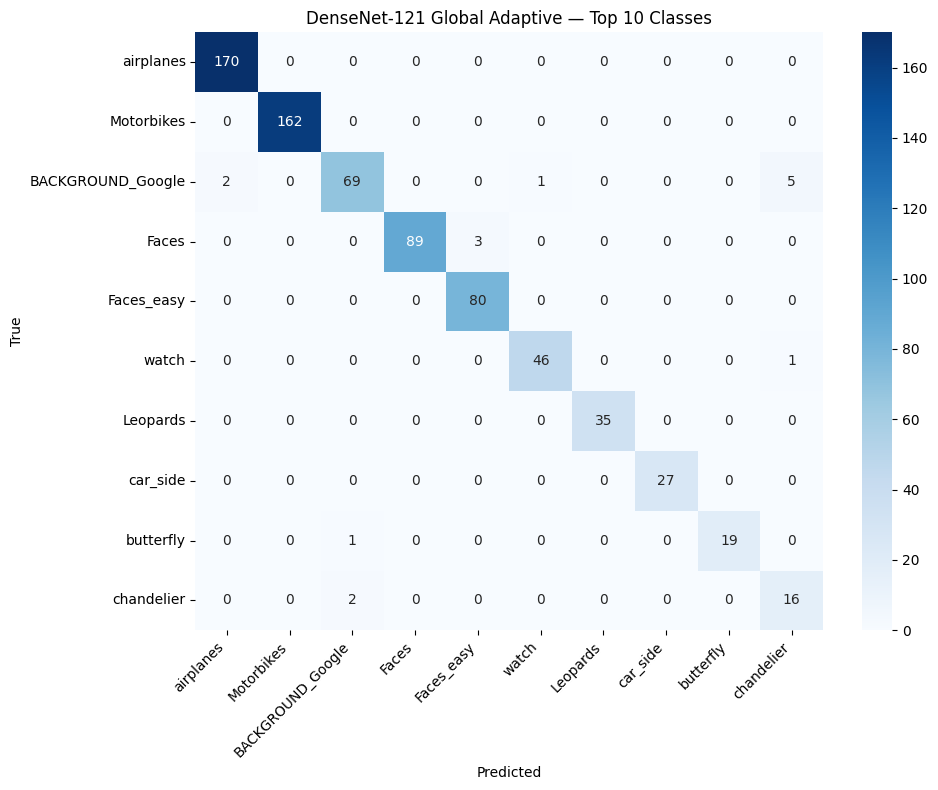

In [44]:
print("\n" + "=" * 60)
print("TEST EVALUATION — Global Adaptive Finetuning")
print("=" * 60)

classes = dataset.classes

# ResNet-50
acc_res_g, f1_res_g, cm_res_g, _, _ = evaluate_model(
    model_res_global, test_loader, device, classes)

# DenseNet-121
acc_den_g, f1_den_g, cm_den_g, _, _ = evaluate_model(
    model_den_global, test_loader, device, classes)

print(f"\nResNet-50    | Test Acc: {acc_res_g:.2f}% | F1: {f1_res_g:.4f} | "
      f"Trainable: {res_g_train:,} | Time: {time_res_global:.1f}s")
print(f"DenseNet-121 | Test Acc: {acc_den_g:.2f}% | F1: {f1_den_g:.4f} | "
      f"Trainable: {den_g_train:,} | Time: {time_den_global:.1f}s")

# Loss + accuracy curves
plot_curves(hist_res_global, "ResNet-50 Global Adaptive")
plot_curves(hist_den_global, "DenseNet-121 Global Adaptive")

# Confusion matrices
plot_top10_confusion(cm_res_g, classes, "ResNet-50 Global Adaptive — Top 10 Classes")
plot_top10_confusion(cm_den_g, classes, "DenseNet-121 Global Adaptive — Top 10 Classes")

In [45]:
print("\n" + "=" * 62)
print("COMPARATIVE ANALYSIS — Global Adaptive Finetuning")
print("=" * 62)
print(f"{'Metric':<32} {'ResNet-50':>14} {'DenseNet-121':>14}")
print("-" * 62)
print(f"{'Method':<32} {'Global Adapt':>14} {'Global Adapt':>14}")
print(f"{'Optimizer':<32} {'Adam':>14} {'Adam':>14}")
print(f"{'Learning Rate':<32} {'1e-4':>14} {'1e-3':>14}")
print(f"{'Scheduler':<32} {'StepLR':>14} {'StepLR':>14}")
print(f"{'Total Params':<32} {res_g_total:>14,} {den_g_total:>14,}")
print(f"{'Trainable Params':<32} {res_g_train:>14,} {den_g_train:>14,}")
print(f"{'Trainable %':<32} "
      f"{100*res_g_train/res_g_total:>13.2f}% "
      f"{100*den_g_train/den_g_total:>13.2f}%")
print(f"{'Best Val Acc (%)':<32} {best_res_global:>14.2f} {best_den_global:>14.2f}")
print(f"{'Test Acc (%)':<32} {acc_res_g:>14.2f} {acc_den_g:>14.2f}")
print(f"{'Macro F1':<32} {f1_res_g:>14.4f} {f1_den_g:>14.4f}")
print(f"{'Training Time (s)':<32} {time_res_global:>14.1f} {time_den_global:>14.1f}")


COMPARATIVE ANALYSIS — Global Adaptive Finetuning
Metric                                ResNet-50   DenseNet-121
--------------------------------------------------------------
Method                             Global Adapt   Global Adapt
Optimizer                                  Adam           Adam
Learning Rate                              1e-4           1e-3
Scheduler                                StepLR         StepLR
Total Params                         23,717,030      7,058,406
Trainable Params                     22,353,190      5,537,062
Trainable %                              94.25%         78.45%
Best Val Acc (%)                          85.89          86.43
Test Acc (%)                              85.52          84.59
Macro F1                                 0.7779         0.7677
Training Time (s)                         256.3          666.8
